# Neural Caption-Image Retrieval (UE24CS352A, Problem 36)
GPU runtime required. Run the cells in order. Feature extraction and finished runs are cached in Google Drive, so after a disconnect just rerun from the top.

## 1. Setup

In [16]:
!pip -q install reportlab

import os, io, re, json, random, subprocess, time, shutil
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd, requests
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision, torchvision.transforms as T
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

TEAM_MEMBERS = "Name 1 (SRN), Name 2 (SRN)"
PROBLEM_NO = 59

CFG = dict(seed=0, n_train=40000, n_test=1000, n_val=500,
           emb_dim=1024, glove_dim=300, max_len=30,
           batch=128, lr=2e-4, epochs=25, patience=5, dropout=0.2)

dev = "cuda" if torch.cuda.is_available() else "cpu"
assert dev == "cuda", "switch the runtime to a GPU"

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def sh(cmd):
    subprocess.run(cmd, shell=True, check=True)

try:
    from google.colab import drive
    drive.mount("/content/drive")
    CACHE = "/content/drive/MyDrive/caption_retrieval"
except Exception:
    CACHE = "cache"
os.makedirs(CACHE, exist_ok=True)
os.makedirs("data", exist_ok=True)
OUT = "outputs"
os.makedirs(OUT, exist_ok=True)
seed_all(CFG["seed"])
print("cache dir:", CACHE)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
cache dir: /content/drive/MyDrive/caption_retrieval


## 2. Data

In [17]:
if not os.path.exists("data/annotations/captions_train2017.json"):
    sh("wget -q -P data http://images.cocodataset.org/annotations/annotations_trainval2017.zip")
    sh("unzip -q -o data/annotations_trainval2017.zip annotations/captions_train2017.json annotations/captions_val2017.json -d data")

def load_caps(name):
    a = json.load(open(f"data/annotations/captions_{name}2017.json"))
    files = {i["id"]: i["file_name"] for i in a["images"]}
    caps = {}
    for x in a["annotations"]:
        caps.setdefault(x["image_id"], []).append(x["caption"].strip())
    return [(f"http://images.cocodataset.org/{name}2017/{files[i]}", c[:5])
            for i, c in sorted(caps.items()) if len(c) >= 5]

MANIFEST = f"{CACHE}/manifest_{CFG['n_train']}.json"
if os.path.exists(MANIFEST):
    items = json.load(open(MANIFEST))
else:
    val_items, train_items = load_caps("val"), load_caps("train")
    random.Random(CFG["seed"]).shuffle(val_items)
    train_items = random.Random(CFG["seed"]).sample(train_items, CFG["n_train"])
    items = val_items[:CFG["n_test"] + CFG["n_val"]] + train_items
    json.dump(items, open(MANIFEST, "w"))

urls = [u for u, _ in items]
n_te, n_va = CFG["n_test"], CFG["n_val"]
bounds = {"test": (0, n_te), "val": (n_te, n_te + n_va), "train": (n_te + n_va, len(items))}
print({k: hi - lo for k, (lo, hi) in bounds.items()}, "images")

{'test': 1000, 'val': 500, 'train': 40000} images


## 3. Image features (VGG-19 fc7, center crop)
Images are streamed from the COCO server and never stored. Features are saved to Drive in chunks of 2,000.

In [18]:
CH = 2000
chunk_file = lambda k: f"{CACHE}/fc7_{k // CH:03d}.npy"
todo = [k for k in range(0, len(urls), CH) if not os.path.exists(chunk_file(k))]

tf = T.Compose([T.Resize(256), T.CenterCrop(224), T.ToTensor(),
                T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

class ImgSet(Dataset):
    def __init__(self, u): self.u = u
    def __len__(self): return len(self.u)
    def __getitem__(self, k):
        for t in range(5):
            try:
                r = requests.get(self.u[k], timeout=20)
                return tf(Image.open(io.BytesIO(r.content)).convert("RGB"))
            except Exception:
                time.sleep(1 + t)
        raise RuntimeError("download failed: " + self.u[k])

if todo:
    vgg = torchvision.models.vgg19(weights=torchvision.models.VGG19_Weights.IMAGENET1K_V1).to(dev).eval()
    fc7 = nn.Sequential(vgg.features, vgg.avgpool, nn.Flatten(), *list(vgg.classifier.children())[:5])
    for k in tqdm(todo, desc="chunks"):
        loader = DataLoader(ImgSet(urls[k:k + CH]), batch_size=16, num_workers=16)
        out = []
        with torch.no_grad():
            for x in loader:
                with torch.autocast("cuda"):
                    out.append(fc7(x.to(dev)).float().cpu())
        np.save(chunk_file(k), torch.cat(out).numpy().astype(np.float16))
    del vgg, fc7

feats = np.concatenate([np.load(chunk_file(k)) for k in range(0, len(urls), CH)]).astype(np.float32)
FEAT_STD = float(feats[bounds["train"][0]:].std())
feats /= FEAT_STD
print(feats.shape)

(41500, 4096)


## 4. Text and GloVe

In [19]:
def tokenize(s):
    return re.findall(r"[a-z0-9]+", s.lower())

caps = [[tokenize(c) for c in cs] for _, cs in items]
cnt = Counter(w for cs in caps for c in cs for w in c)
itos = ["<pad>", "<unk>"] + sorted(cnt)
stoi = {w: k for k, w in enumerate(itos)}
print("vocab size:", len(itos))

def load_glove(needed):
    try:
        from huggingface_hub import snapshot_download
        p = snapshot_download("sentence-transformers/average_word_embeddings_glove.6B.300d")
        d = f"{p}/0_WordEmbeddings"
        words = json.load(open(f"{d}/whitespacetokenizer_config.json"))["vocab"]
        sd = torch.load(f"{d}/pytorch_model.bin", map_location="cpu")
        mat = next(v for v in sd.values() if v.dim() == 2).numpy()
        assert len(words) == mat.shape[0]
        return {w: mat[k] for k, w in enumerate(words) if w in needed}
    except Exception as e:
        print("hub download failed:", type(e).__name__, "- using the stanford zip")
        if not os.path.exists("data/glove.6B.300d.txt"):
            sh("wget -q -P data https://downloads.cs.stanford.edu/nlp/data/glove.6B.zip")
            sh("unzip -q -o data/glove.6B.zip glove.6B.300d.txt -d data")
        out = {}
        with open("data/glove.6B.300d.txt", encoding="utf8") as f:
            for line in f:
                w, rest = line.split(" ", 1)
                if w in needed:
                    out[w] = np.asarray(rest.split(), dtype=np.float32)
        return out

gv = load_glove(set(itos))
G = np.zeros((len(itos), CFG["glove_dim"]), dtype=np.float32)
for w, vec in gv.items():
    G[stoi[w]] = vec
print(f"glove coverage: {len(gv)}/{len(itos) - 2}")

rs = np.random.RandomState(CFG["seed"])
emb_init = G.copy()
miss = np.where(~np.any(G, axis=1))[0]
emb_init[miss] = rs.normal(0, 0.1, (len(miss), CFG["glove_dim"]))
emb_init[0] = 0
emb_rand = rs.normal(0, 0.1, G.shape).astype(np.float32)
emb_rand[0] = 0
G, emb_init, emb_rand = [torch.tensor(a).to(dev) for a in (G, emb_init, emb_rand)]

vocab size: 17406


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

glove coverage: 15472/17404


## 5. Splits

In [20]:
L = CFG["max_len"]

def make_split(lo, hi):
    seqs, gt = [], []
    for k in range(lo, hi):
        for c in caps[k]:
            seqs.append([stoi[w] for w in c][:L] or [1])
            gt.append(k - lo)
    x = torch.zeros(len(seqs), L, dtype=torch.long)
    for r, s in enumerate(seqs):
        x[r, :len(s)] = torch.tensor(s)
    return dict(x=x.to(dev), lens=torch.tensor([len(s) for s in seqs]).to(dev),
                gt=torch.tensor(gt).to(dev), img=torch.tensor(feats[lo:hi]).to(dev), n=hi - lo)

tr, va, te = (make_split(*bounds[k]) for k in ("train", "val", "test"))
print({k: s["x"].shape[0] for k, s in zip(("train", "val", "test"), (tr, va, te))}, "captions")

{'train': 200000, 'val': 2500, 'test': 5000} captions


## 6. Metrics and baseline (ridge regression on mean GloVe)

In [21]:
def ranks_from_scores(S, gt):
    correct = S[torch.arange(len(gt), device=S.device), gt].unsqueeze(1)
    return (S > correct).sum(1) + 1

def summarize(r):
    r = r.float()
    return {"R@1": (r <= 1).float().mean().item() * 100, "R@5": (r <= 5).float().mean().item() * 100,
            "R@10": (r <= 10).float().mean().item() * 100, "MedR": r.median().item(), "MeanR": r.mean().item()}

def mean_glove(S, chunk=20000):
    out = []
    for a in range(0, S["x"].shape[0], chunk):
        out.append(G[S["x"][a:a + chunk]].sum(1) / S["lens"][a:a + chunk].unsqueeze(1))
    return torch.cat(out)

def ridge_stats(S, chunk=20000):
    X = mean_glove(S)
    d, p, n = X.shape[1], S["img"].shape[1], X.shape[0]
    xtx = torch.zeros(d, d, device=dev, dtype=torch.float64)
    xty = torch.zeros(d, p, device=dev, dtype=torch.float64)
    xs = torch.zeros(d, device=dev, dtype=torch.float64)
    ys = torch.zeros(p, device=dev, dtype=torch.float64)
    for a in range(0, n, chunk):
        x = X[a:a + chunk].double()
        y = S["img"][S["gt"][a:a + chunk]].double()
        xtx += x.T @ x; xty += x.T @ y; xs += x.sum(0); ys += y.sum(0)
    return xtx, xty, xs / n, ys / n, n

def ridge_solve(st, lam):
    xtx, xty, xm, ym, n = st
    A = xtx - n * torch.outer(xm, xm) + lam * torch.eye(xtx.shape[0], device=dev, dtype=torch.float64)
    W = torch.linalg.solve(A, xty - n * torch.outer(xm, ym))
    return W.float(), xm.float(), ym.float()

def baseline_scores(params, S):
    W, xm, ym = params
    pred = (mean_glove(S) - xm) @ W + ym
    return -torch.cdist(pred, S["img"]) ** 2

st = ridge_stats(tr)
best = None
for lam in [1, 10, 100, 1000, 10000]:
    params = ridge_solve(st, lam)
    r10 = summarize(ranks_from_scores(baseline_scores(params, va), va["gt"]))["R@10"]
    print(f"lambda={lam:<6} val R@10={r10:.1f}")
    if best is None or r10 > best[0]:
        best = (r10, params)

base_val, base_params = best
base_ranks = ranks_from_scores(baseline_scores(base_params, te), te["gt"])
base_metrics = summarize(base_ranks)
print("baseline test:", {k: round(v, 1) for k, v in base_metrics.items()})

lambda=1      val R@10=32.0
lambda=10     val R@10=31.5
lambda=100    val R@10=29.0
lambda=1000   val R@10=22.9
lambda=10000  val R@10=10.8
baseline test: {'R@1': 4.4, 'R@5': 13.7, 'R@10': 20.6, 'MedR': 82.0, 'MeanR': 190.1}


## 7. Neural model

In [22]:
class Retriever(nn.Module):
    def __init__(self, emb, rnn="gru", bidir=False, sim="euclid"):
        super().__init__()
        D = CFG["emb_dim"]
        self.sim, self.bidir, self.is_lstm = sim, bidir, rnn == "lstm"
        self.margin = 0.2 if sim == "euclid" else 0.05
        self.emb = nn.Embedding.from_pretrained(emb.clone(), freeze=False, padding_idx=0)
        self.rnn = (nn.LSTM if self.is_lstm else nn.GRU)(emb.shape[1], D, batch_first=True, bidirectional=bidir)
        self.proj = nn.Linear(2 * D, D) if bidir else nn.Identity()
        self.img = nn.Sequential(nn.Dropout(CFG["dropout"]), nn.Linear(feats.shape[1], D))
        self.drop = nn.Dropout(CFG["dropout"])

    def post(self, v):
        v = F.normalize(v, dim=-1)
        return v.abs() if self.sim == "order" else v

    def encode_text(self, x, lens):
        packed = nn.utils.rnn.pack_padded_sequence(self.drop(self.emb(x)), lens.cpu(),
                                                   batch_first=True, enforce_sorted=False)
        _, h = self.rnn(packed)
        if self.is_lstm:
            h = h[0]
        v = torch.cat([h[-2], h[-1]], dim=-1) if self.bidir else h[-1]
        return self.post(self.proj(v))

    def encode_img(self, f):
        return self.post(self.img(f))

    def score(self, c, i):
        if self.sim == "euclid":
            return 2 * c @ i.T - 2
        return -(F.relu(c.unsqueeze(1) - i.unsqueeze(0)) ** 2).sum(-1)

def ranking_loss(s, gid, margin):
    d = s.diag().unsqueeze(1)
    same = gid.unsqueeze(0) == gid.unsqueeze(1)
    wrong_img = (margin - d + s).clamp(min=0).masked_fill(same, 0)
    wrong_cap = (margin - d.t() + s).clamp(min=0).masked_fill(same, 0)
    return (wrong_img.sum() + wrong_cap.sum()) / s.shape[0]

@torch.no_grad()
def embed_split(model, S, bs=1000):
    model.eval()
    c = torch.cat([model.encode_text(S["x"][a:a + bs], S["lens"][a:a + bs])
                   for a in range(0, S["x"].shape[0], bs)])
    return c, model.encode_img(S["img"])

@torch.no_grad()
def evaluate(model, S):
    c, i = embed_split(model, S)
    sc = torch.cat([model.score(c[a:a + 100], i) for a in range(0, len(c), 100)])
    r = ranks_from_scores(sc, S["gt"])
    return summarize(r), r

def train_model(name, rnn="gru", bidir=False, sim="euclid", glove=True):
    seed_all(CFG["seed"])
    model = Retriever(emb_init if glove else emb_rand, rnn, bidir, sim).to(dev)
    ck = f"{CACHE}/run_{re.sub('[^a-z0-9]+', '_', name.lower())}_{tr['n']}.pt"
    if os.path.exists(ck):
        d = torch.load(ck, map_location=dev)
        model.load_state_dict(d["state"])
        hist, best_val = d["hist"], d["val"]
        print(f"[{name}] loaded saved run")
    else:
        opt = torch.optim.Adam(model.parameters(), lr=CFG["lr"])
        B, n = CFG["batch"], tr["x"].shape[0]
        hist, best_val, best_state, bad = [], -1, None, 0
        t0 = time.time()
        for ep in range(1, CFG["epochs"] + 1):
            model.train()
            perm = torch.randperm(n, device=dev)
            tot, steps = 0.0, 0
            for a in range(0, n - B + 1, B):
                b = perm[a:a + B]
                c = model.encode_text(tr["x"][b], tr["lens"][b])
                i = model.encode_img(tr["img"][tr["gt"][b]])
                loss = ranking_loss(model.score(c, i), tr["gt"][b], model.margin)
                opt.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 2.0)
                opt.step()
                tot += loss.item(); steps += 1
            v = evaluate(model, va)[0]["R@10"]
            hist.append((tot / steps, v))
            print(f"[{name}] epoch {ep:2d}  loss {tot / steps:.3f}  val R@10 {v:.1f}  ({time.time() - t0:.0f}s)")
            if v > best_val:
                best_val, bad = v, 0
                best_state = {k: t.detach().clone() for k, t in model.state_dict().items()}
            else:
                bad += 1
                if bad >= CFG["patience"]:
                    print(f"[{name}] early stop")
                    break
        model.load_state_dict(best_state)
        torch.save(dict(state=best_state, hist=hist, val=best_val), ck)
    metrics, ranks = evaluate(model, te)
    print(f"[{name}] best val R@10 {best_val:.1f}, test R@10 {metrics['R@10']:.1f}\n")
    return dict(model=model, hist=hist, val=best_val, test=metrics, ranks=ranks)

## 8. Train

In [23]:
experiments = {
    "GRU (random init)":       dict(rnn="gru", glove=False),
    "GRU + GloVe":             dict(rnn="gru", glove=True),
    "LSTM + GloVe":            dict(rnn="lstm", glove=True),
    "GRU + GloVe (order emb)": dict(rnn="gru", glove=True, sim="order"),
}
runs = {name: train_model(name, **kw) for name, kw in experiments.items()}

[GRU (random init)] loaded saved run
[GRU (random init)] best val R@10 89.6, test R@10 79.5

[GRU + GloVe] loaded saved run
[GRU + GloVe] best val R@10 90.4, test R@10 80.4

[LSTM + GloVe] loaded saved run
[LSTM + GloVe] best val R@10 90.3, test R@10 80.3

[GRU + GloVe (order emb)] loaded saved run
[GRU + GloVe (order emb)] best val R@10 90.8, test R@10 80.7



## 9. Results

,R@1,R@5,R@10,MedR,MeanR
Method,,,,,
Baseline (ridge on mean GloVe),4.4,13.7,20.6,82.0,190.1
GRU (random init),30.3,64.6,79.5,3.0,11.4
GRU + GloVe,29.5,65.1,80.4,3.0,10.2
LSTM + GloVe,31.1,66.2,80.3,3.0,10.2
GRU + GloVe (order emb),32.3,67.1,80.7,3.0,9.7


best by validation R@10: GRU + GloVe (order emb)


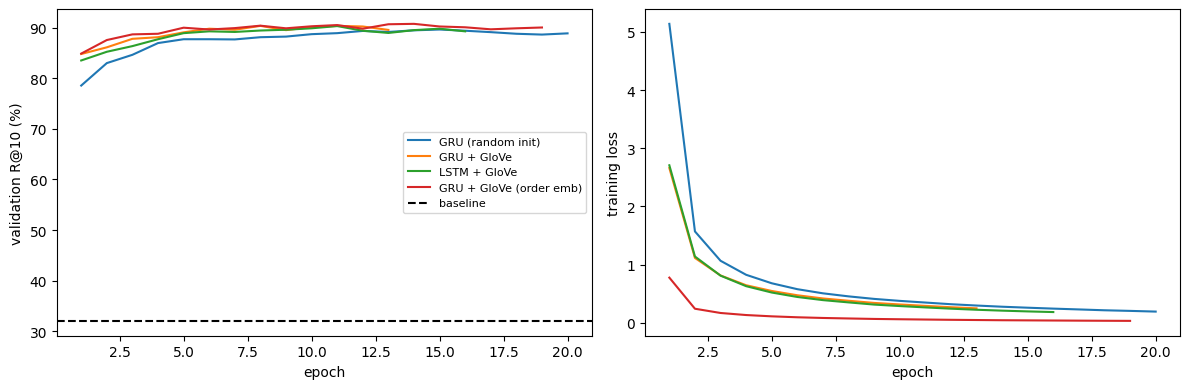

In [24]:
rows = [dict(Method="Baseline (ridge on mean GloVe)", **base_metrics)]
rows += [dict(Method=n, **r["test"]) for n, r in runs.items()]
results = pd.DataFrame(rows).set_index("Method").round(1)
display(results)
results.to_csv(f"{OUT}/results.csv")

best_name = max(runs, key=lambda n: runs[n]["val"])
print("best by validation R@10:", best_name)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for n, r in runs.items():
    ax[0].plot(range(1, len(r["hist"]) + 1), [h[1] for h in r["hist"]], label=n)
    ax[1].plot(range(1, len(r["hist"]) + 1), [h[0] for h in r["hist"]], label=n)
ax[0].axhline(base_val, color="k", ls="--", label="baseline")
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("validation R@10 (%)"); ax[0].legend(fontsize=8)
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("training loss")
plt.tight_layout()
plt.savefig(f"{OUT}/curves.png", dpi=150)
plt.show()

## 10. Caption length

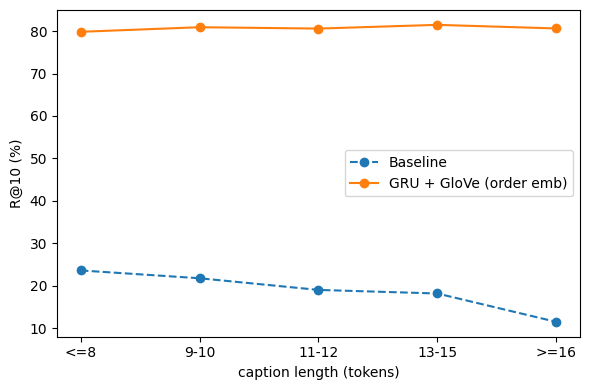

queries per bin: {'<=8': 783, '9-10': 2162, '11-12': 1313, '13-15': 577, '>=16': 165}


In [25]:
lens_te = te["lens"].cpu().numpy()
edges = [(0, 8), (9, 10), (11, 12), (13, 15), (16, 99)]
labels = ["<=8", "9-10", "11-12", "13-15", ">=16"]

def r10_by_len(ranks):
    r = ranks.cpu().numpy()
    return [100 * (r[(lens_te >= lo) & (lens_te <= hi)] <= 10).mean() for lo, hi in edges]

plt.figure(figsize=(6, 4))
plt.plot(labels, r10_by_len(base_ranks), "o--", label="Baseline")
plt.plot(labels, r10_by_len(runs[best_name]["ranks"]), "o-", label=best_name)
plt.xlabel("caption length (tokens)"); plt.ylabel("R@10 (%)"); plt.legend()
plt.tight_layout()
plt.savefig(f"{OUT}/length.png", dpi=150)
plt.show()
print("queries per bin:", dict(zip(labels, [int(((lens_te >= lo) & (lens_te <= hi)).sum()) for lo, hi in edges])))

## 11. Retrieval demo (test gallery)

gallery images:   0%|          | 0/1000 [00:00<?, ?it/s]

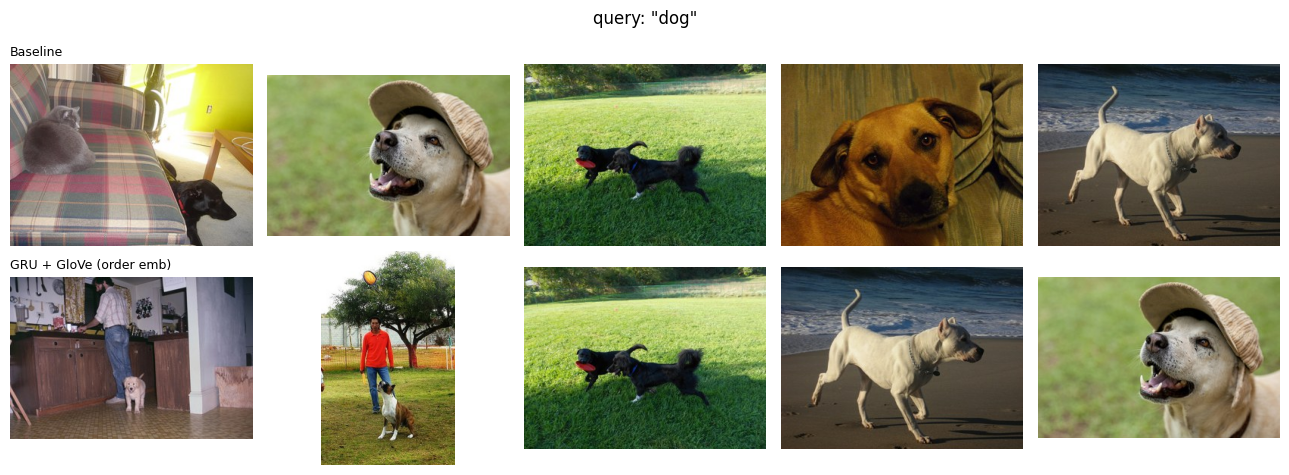

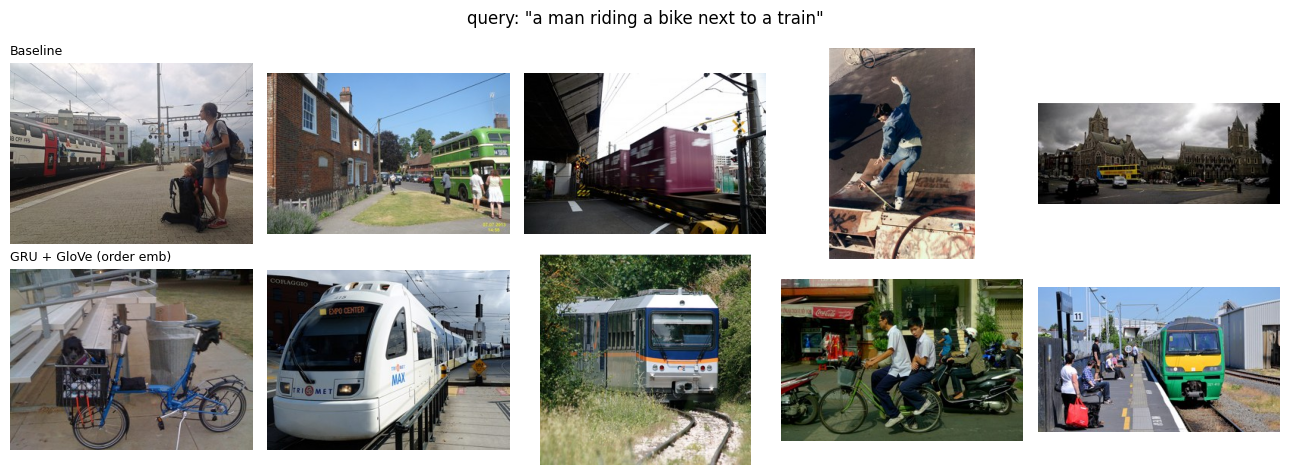

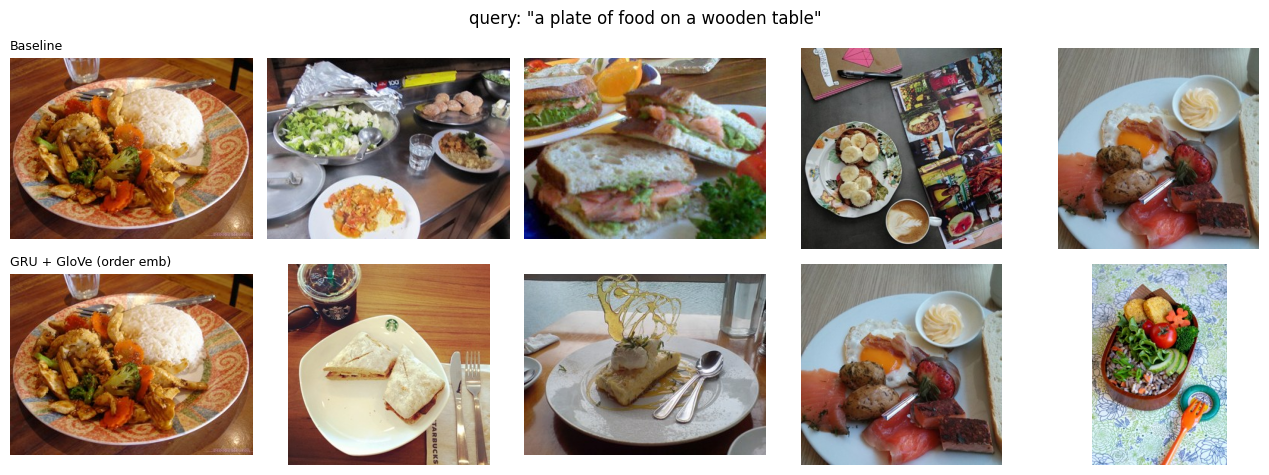

In [26]:
GAL = "demo_bundle/images"
os.makedirs(GAL, exist_ok=True)

def fetch(k):
    dst = f"{GAL}/{k:04d}.jpg"
    if os.path.exists(dst):
        return
    for t in range(5):
        try:
            im = Image.open(io.BytesIO(requests.get(urls[k], timeout=20).content)).convert("RGB")
            im.thumbnail((320, 320)); im.save(dst, quality=88)
            return
        except Exception:
            time.sleep(1 + t)
    raise RuntimeError(urls[k])

with ThreadPoolExecutor(32) as ex:
    list(tqdm(ex.map(fetch, range(n_te)), total=n_te, desc="gallery images"))

@torch.no_grad()
def search(q, k=5):
    toks = [stoi.get(w, 1) for w in tokenize(q)][:L] or [1]
    x = torch.zeros(1, L, dtype=torch.long); x[0, :len(toks)] = torch.tensor(toks)
    x, ln = x.to(dev), torch.tensor([len(toks)])
    W, xm, ym = base_params
    pred = (G[x].sum(1) / ln.to(dev).unsqueeze(1) - xm) @ W + ym
    out = {"Baseline": (-torch.cdist(pred, te["img"]) ** 2)[0].topk(k).indices.tolist()}
    m = runs[best_name]["model"].eval()
    out[best_name] = m.score(m.encode_text(x, ln), m.encode_img(te["img"]))[0].topk(k).indices.tolist()
    return out

def show(q, k=5, save=None):
    res = search(q, k)
    fig, axes = plt.subplots(len(res), k, figsize=(2.6 * k, 2.4 * len(res)))
    for r, (name, idx) in enumerate(res.items()):
        for c, j in enumerate(idx):
            axes[r][c].imshow(Image.open(f"{GAL}/{j:04d}.jpg")); axes[r][c].axis("off")
            if c == 0:
                axes[r][c].set_title(name, fontsize=9, loc="left")
    fig.suptitle(f'query: "{q}"')
    plt.tight_layout()
    if save: plt.savefig(save, dpi=130)
    plt.show()

show("dog", save=f"{OUT}/demo_dog.png")
show("a man riding a bike next to a train")
show("a plate of food on a wooden table")

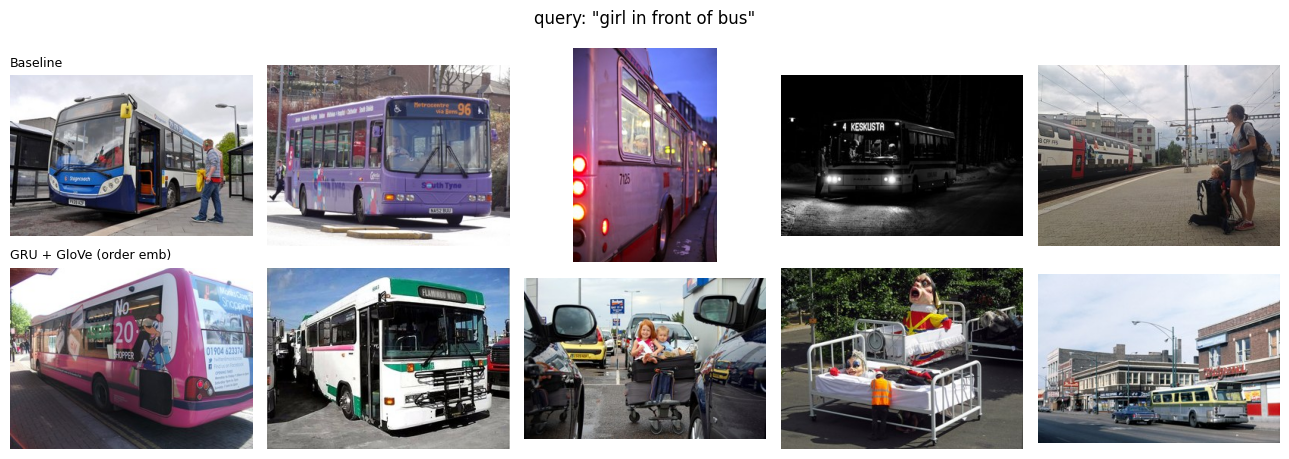

In [27]:
query = "girl in front of bus"  #@param {type:"string"}
show(query)

## 12. Export demo bundle

In [28]:
BUNDLE = "demo_bundle"
kw = experiments[best_name]
m = runs[best_name]["model"]
torch.save(dict(state=m.state_dict(), name=best_name, rnn=kw["rnn"], bidir=kw.get("bidir", False),
                sim=kw.get("sim", "euclid"), emb_dim=CFG["emb_dim"], max_len=CFG["max_len"],
                feat_dim=int(feats.shape[1]), vocab_size=len(itos), glove_dim=CFG["glove_dim"]),
           f"{BUNDLE}/model.pt")
json.dump(itos, open(f"{BUNDLE}/vocab.json", "w"))
torch.save(dict(W=base_params[0].cpu(), xm=base_params[1].cpu(), ym=base_params[2].cpu(), G=G.cpu()),
           f"{BUNDLE}/baseline.pt")
np.save(f"{BUNDLE}/gallery_feats.npy", te["img"].cpu().numpy())
json.dump([f"{k:04d}.jpg" for k in range(n_te)], open(f"{BUNDLE}/images.json", "w"))
json.dump(results.reset_index().to_dict("records"), open(f"{BUNDLE}/results.json", "w"))

shutil.make_archive("demo_bundle", "zip", BUNDLE)
print("bundle size (MB):", round(os.path.getsize("demo_bundle.zip") / 1e6, 1))
try:
    from google.colab import files
    shutil.copy("demo_bundle.zip", "/content/drive/MyDrive/demo_bundle.zip")
    print("copied to Drive: MyDrive/demo_bundle.zip")
    files.download("demo_bundle.zip")
except Exception as e:
    print("kept locally:", type(e).__name__)

bundle size (MB): 98.3
copied to Drive: MyDrive/demo_bundle.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 13. README and write-up PDF

In [29]:
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.units import cm
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle, Image as RLImage
from reportlab.lib import colors

bm, bn = base_metrics, runs[best_name]["test"]
pre = runs["GRU + GloVe"]["test"]["R@10"] - runs["GRU (random init)"]["test"]["R@10"]
gain = bn["R@10"] - bm["R@10"]
n_tr = bounds["train"][1] - bounds["train"][0]

try:
    table_txt = results.to_markdown()
except Exception:
    table_txt = results.to_string()

readme = f'''# Neural Caption-Image Retrieval

UE24CS352A Machine Learning mini-project, problem {PROBLEM_NO}.
Team: {TEAM_MEMBERS}

Text queries are matched to images in a shared embedding space. Captions go through a GRU/LSTM on GloVe vectors, images are VGG-19 fc7 features, and a ranking loss with in-batch negatives aligns the two. A ridge regression on averaged GloVe vectors is the baseline.

## Training
1. Open `caption_image_retrieval.ipynb` in Google Colab with a GPU runtime and run all cells.
2. It streams {n_tr:,} COCO train2017 images plus 1,500 val2017 images for feature extraction (cached in Google Drive in chunks) and downloads GloVe 6B/300d.
3. Outputs (metrics, plots, demo bundle, write-up) are written to `outputs/` and `demo_bundle.zip`.

## Demo without retraining
Put `demo.ipynb` and `demo_bundle.zip` in the same folder (or in Google Drive when using Colab) and run all cells. CPU is enough. Edit the `query` cell to search the 1,000 test images.

Dependencies for local use: `pip install torch numpy matplotlib pillow pandas jupyter`.

## Files
- `caption_image_retrieval.ipynb`: feature extraction, baseline, neural models, evaluation, export
- `demo.ipynb`: loads the exported model and searches the test gallery
- `outputs/results.csv`, `outputs/curves.png`, `outputs/length.png`, `outputs/writeup.pdf`

## Results (1,000 test images, 5,000 queries)
{table_txt}
'''
open(f"{OUT}/README.md", "w").write(readme)

ss = getSampleStyleSheet()
body = ParagraphStyle("b", parent=ss["BodyText"], fontSize=9, leading=11.5, spaceAfter=3)
h = ParagraphStyle("h", parent=ss["Heading3"], fontSize=10.5, spaceBefore=5, spaceAfter=2)
doc = SimpleDocTemplate(f"{OUT}/writeup.pdf", pagesize=A4, leftMargin=1.8*cm, rightMargin=1.8*cm,
                        topMargin=1.5*cm, bottomMargin=1.5*cm)
P = lambda t, s=body: Paragraph(t, s)

tbl_rows = [["Method", "R@1", "R@5", "R@10", "MedR", "MeanR"]]
for name, r in results.iterrows():
    tbl_rows.append([name] + [f"{r[c]:.1f}" for c in ["R@1", "R@5", "R@10", "MedR", "MeanR"]])
tbl = Table(tbl_rows, hAlign="LEFT")
tbl.setStyle(TableStyle([("FONTSIZE", (0, 0), (-1, -1), 8), ("GRID", (0, 0), (-1, -1), 0.4, colors.grey),
                         ("BACKGROUND", (0, 0), (-1, 0), colors.lightgrey)]))
figs = Table([[RLImage(f"{OUT}/curves.png", width=9.2*cm, height=3.7*cm),
               RLImage(f"{OUT}/length.png", width=5.6*cm, height=3.7*cm)]], hAlign="LEFT")

story = [
    P(f"<b>Neural Caption-Image Retrieval</b> (UE24CS352A, Problem {PROBLEM_NO})", ss["Title"]),
    P(TEAM_MEMBERS),
    P("Problem statement", h),
    P("Given a free-text query describing a picture, return the most relevant images from a collection. "
      "The input is a gallery of raw images and a query sentence; the output is a ranked list of images."),
    P("Dataset", h),
    P(f"MS-COCO captions, 5 human-written captions per image. Training uses {n_tr:,} randomly chosen images from "
      f"train2017; validation ({n_va}) and test ({n_te}) images come from val2017, so no image appears in more than "
      f"one split. Every caption of a test image is a query ({5*n_te:,} queries over a gallery of {n_te:,} images). "
      f"Captions are lower-cased and split on alphanumeric runs. Images are represented by 4096-d fc7 activations of "
      f"an ImageNet-pretrained VGG-19 (center crop 224); words by 300-d GloVe vectors."),
    P("Approach", h),
    P("<b>Baseline.</b> A caption is the mean of its GloVe vectors. A ridge regression maps this vector to the VGG "
      "feature of its image (closed form, regularisation chosen on validation); retrieval is nearest neighbour in "
      "VGG space. <b>Neural model.</b> Captions are encoded by a GRU or LSTM over GloVe-initialised, fine-tuned "
      "embeddings; images pass through a linear layer into the same 1024-d space. Training uses a bidirectional "
      "hinge ranking loss where every other caption/image in the mini-batch is a negative (captions of the same "
      "image are masked out). Two similarity functions were compared: Euclidean distance between unit vectors and "
      "the order-embedding penalty on non-negative vectors. Compared variants: random vs GloVe initialisation, "
      "GRU vs LSTM, Euclidean vs order similarity."),
    P("Implementation", h),
    P(f"PyTorch in a single Colab notebook. VGG features are extracted once and cached; models train on the cached "
      f"features with Adam (lr {CFG['lr']}), batch size {CFG['batch']}, dropout {CFG['dropout']}, gradient clipping, "
      f"at most {CFG['epochs']} epochs with early stopping on validation R@10 (patience {CFG['patience']}). "
      f"Metrics are Recall@K (share of queries whose true image is in the top K) and the mean and median rank of "
      f"the true image."),
    P("Results", h),
    tbl, Spacer(1, 4), figs,
    P("Left: validation R@10 per epoch. Right: R@10 by caption length for the baseline and the best neural model.",
      ParagraphStyle("c", parent=body, fontSize=7.5)),
    P("Conclusions", h),
    P(f"The best neural model by validation R@10 was <b>{best_name}</b> with test R@10 of {bn['R@10']:.1f}% "
      f"(R@1 {bn['R@1']:.1f}%), against {bm['R@10']:.1f}% R@10 for the ridge baseline, a difference of {gain:+.1f} "
      f"points. GloVe initialisation instead of random embeddings changed GRU R@10 by {pre:+.1f} points. Averaging "
      f"word vectors discards word order and the relations between objects, which the recurrent encoders can "
      f"model. Limitations: training used a {n_tr:,}-image subset of COCO rather than the full set, image features "
      f"are frozen, and rare words that never occur in the captions cannot be retrieved well. Natural extensions "
      f"are region-level attention over image features, a stronger visual backbone and training on the full dataset."),
]
doc.build(story)

shutil.make_archive("project_outputs", "zip", OUT)
try:
    from google.colab import files
    files.download("project_outputs.zip")
except Exception:
    print("saved to project_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>